# EDA — DATAMARCA: transacciones (POS) y logs de e-commerce

Análisis exploratorio en dos partes: **Parte 1** transacciones de punto de venta (CSV, 5.000 registros) y **Parte 2** logs de eventos de e-commerce (JSON), más una sección que cruza ambas fuentes.

**Contenido**
1. Carga y vista general
2. Calidad de datos
3. Ingeniería de variables
4. Análisis univariado
5. Análisis bivariado
6. Patrones temporales
7. Cruces entre variables y pruebas estadísticas
8. Conclusiones de la Parte 1

**Parte 2 — Logs de e-commerce** (secciones 9 a 15)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titleweight"] = "bold"
pd.options.display.float_format = "{:,.2f}".format

fmt_cop = mtick.FuncFormatter(lambda x, _: f"${x:,.0f}")

## 1. Carga y vista general

In [2]:
df = pd.read_csv("DATAMARCA_transacciones_5000_real.csv", parse_dates=["timestamp"])
print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
df.head(10)

Filas: 5,000 | Columnas: 6


,transaction_id,timestamp,store_id,product_category,amount_cop,payment_method
0,TXN10000,2026-09-15 08:02:06,MED-01,Snacks,74979,App
1,TXN10001,2026-09-15 08:02:39,BOG-02,Frutas,62048,App
2,TXN10002,2026-09-15 08:06:44,BAR-01,Bebidas,17878,App
3,TXN10003,2026-09-15 08:15:17,BOG-01,Panadería,4715,Tarjeta
4,TXN10004,2026-09-15 08:39:12,MED-02,Lácteos,8920,Efectivo
5,TXN10005,2026-09-15 08:46:15,MED-01,Panadería,83988,Efectivo
6,TXN10006,2026-09-15 08:50:51,BOG-02,Lácteos,61122,Tarjeta
7,TXN10007,2026-09-15 08:54:27,MED-02,Licores,51123,Tarjeta
8,TXN10008,2026-09-15 09:08:58,MED-02,Licores,8300,Efectivo
9,TXN10009,2026-09-15 09:28:07,CAL-01,Carnes,47965,Tarjeta


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   transaction_id    5000 non-null   str           
 1   timestamp         5000 non-null   datetime64[us]
 2   store_id          5000 non-null   str           
 3   product_category  5000 non-null   str           
 4   amount_cop        5000 non-null   int64         
 5   payment_method    5000 non-null   str           
dtypes: datetime64[us](1), int64(1), str(4)
memory usage: 234.5 KB


In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
transaction_id,5000,5000,TXN10000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
timestamp,5000,NaN,NaN,NaN,2026-09-30 17:32:06.455200,2026-09-15 08:02:06,2026-09-23 05:46:35,2026-09-30 20:36:10,2026-10-08 07:27:10.750000,2026-10-15 17:59:48,NaN
store_id,5000,6,BOG-02,905,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_category,5000,10,Snacks,514,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount_cop,"5,000.00",NaN,NaN,NaN,"47,089.01","2,005.00","15,335.00","33,650.00","63,212.50","413,280.00","44,477.78"
payment_method,5000,4,Tarjeta,2296,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Calidad de datos
Revisamos nulos, duplicados, llaves, rangos y consistencia de categorías.

In [5]:
calidad = pd.DataFrame({
    "nulos": df.isna().sum(),
    "% nulos": df.isna().mean() * 100,
    "únicos": df.nunique(),
})
display(calidad)

print("Filas duplicadas (completas):", df.duplicated().sum())
print("transaction_id duplicados:   ", df["transaction_id"].duplicated().sum())
print("timestamps duplicados:       ", df["timestamp"].duplicated().sum())
print("Orden cronológico creciente: ", df["timestamp"].is_monotonic_increasing)
print("Montos <= 0:                 ", (df["amount_cop"] <= 0).sum())
print("Rango de fechas:", df["timestamp"].min(), "→", df["timestamp"].max())

,nulos,% nulos,únicos
transaction_id,0,0.00,5000
timestamp,0,0.00,4995
store_id,0,0.00,6
product_category,0,0.00,10
amount_cop,0,0.00,4868
payment_method,0,0.00,4


Filas duplicadas (completas): 0
transaction_id duplicados:    0
timestamps duplicados:        5
Orden cronológico creciente:  True
Montos <= 0:                  0
Rango de fechas: 2026-09-15 08:02:06 → 2026-10-15 17:59:48


In [6]:
# Consistencia de categorías (espacios, mayúsculas/minúsculas)
for c in ["store_id", "product_category", "payment_method"]:
    vals = df[c].unique()
    limpio = pd.Series(vals).str.strip().str.lower().nunique()
    print(f"{c:18s} valores={len(vals):2d} | tras normalizar={limpio:2d} | {sorted(vals)}")

# Formato del ID
print("\nID con formato TXN#####:", df["transaction_id"].str.fullmatch(r"TXN\d{5}").all())

store_id           valores= 6 | tras normalizar= 6 | ['BAR-01', 'BOG-01', 'BOG-02', 'CAL-01', 'MED-01', 'MED-02']
product_category   valores=10 | tras normalizar=10 | ['Aseo', 'Bebidas', 'Carnes', 'Frutas', 'Granos', 'Licores', 'Lácteos', 'Panadería', 'Snacks', 'Verduras']
payment_method     valores= 4 | tras normalizar= 4 | ['App', 'Bono', 'Efectivo', 'Tarjeta']

ID con formato TXN#####: True


In [7]:
# Timestamps repetidos: ¿son transacciones distintas en el mismo segundo?
df[df["timestamp"].duplicated(keep=False)].sort_values("timestamp").head(10)

,transaction_id,timestamp,store_id,product_category,amount_cop,payment_method
575,TXN10575,2026-09-18 22:39:15,MED-02,Carnes,87269,Tarjeta
576,TXN10576,2026-09-18 22:39:15,BAR-01,Aseo,145138,Tarjeta
609,TXN10609,2026-09-19 03:20:21,CAL-01,Bebidas,14520,Tarjeta
610,TXN10610,2026-09-19 03:20:21,CAL-01,Bebidas,61656,Efectivo
2317,TXN12317,2026-09-29 15:48:35,MED-02,Carnes,44293,App
2318,TXN12318,2026-09-29 15:48:35,BOG-01,Licores,4229,Tarjeta
4014,TXN14014,2026-10-09 21:44:51,BOG-01,Licores,99277,Efectivo
4015,TXN14015,2026-10-09 21:44:51,CAL-01,Lácteos,180440,Tarjeta
4260,TXN14260,2026-10-11 11:17:13,BOG-01,Aseo,61660,Efectivo
4261,TXN14261,2026-10-11 11:17:13,BOG-01,Granos,5386,Tarjeta


## 3. Ingeniería de variables
Derivamos variables de tiempo y la **ciudad** a partir del prefijo de `store_id`
(`BOG`=Bogotá, `MED`=Medellín, `CAL`=Cali, `BAR`=Barranquilla — *supuesto basado en los códigos*).

In [8]:
ciudades = {"BOG": "Bogotá", "MED": "Medellín", "CAL": "Cali", "BAR": "Barranquilla"}
dias_es = {0: "Lun", 1: "Mar", 2: "Mié", 3: "Jue", 4: "Vie", 5: "Sáb", 6: "Dom"}
orden_dias = list(dias_es.values())

df["fecha"] = df["timestamp"].dt.normalize()
df["hora"] = df["timestamp"].dt.hour
df["dia_semana"] = pd.Categorical(df["timestamp"].dt.dayofweek.map(dias_es), categories=orden_dias, ordered=True)
df["semana"] = df["timestamp"].dt.to_period("W-SUN").dt.start_time
df["es_fin_semana"] = df["timestamp"].dt.dayofweek >= 5
df["ciudad"] = df["store_id"].str[:3].map(ciudades)
df["franja"] = pd.cut(df["hora"], bins=[-1, 5, 11, 17, 23],
                      labels=["Madrugada (0-5)", "Mañana (6-11)", "Tarde (12-17)", "Noche (18-23)"])
df["log_monto"] = np.log10(df["amount_cop"])

df[["timestamp", "store_id", "ciudad", "hora", "dia_semana", "franja", "amount_cop"]].head()

,timestamp,store_id,ciudad,hora,dia_semana,franja,amount_cop
0,2026-09-15 08:02:06,MED-01,Medellín,8,Mar,Mañana (6-11),74979
1,2026-09-15 08:02:39,BOG-02,Bogotá,8,Mar,Mañana (6-11),62048
2,2026-09-15 08:06:44,BAR-01,Barranquilla,8,Mar,Mañana (6-11),17878
3,2026-09-15 08:15:17,BOG-01,Bogotá,8,Mar,Mañana (6-11),4715
4,2026-09-15 08:39:12,MED-02,Medellín,8,Mar,Mañana (6-11),8920


## 4. Análisis univariado

### 4.1 Monto de la transacción (`amount_cop`)

In [9]:
resumen = df["amount_cop"].describe(percentiles=[.01, .05, .25, .5, .75, .9, .95, .99])
resumen["asimetría"] = df["amount_cop"].skew()
resumen["curtosis"] = df["amount_cop"].kurt()
resumen["coef. variación"] = df["amount_cop"].std() / df["amount_cop"].mean()
resumen.to_frame("amount_cop")

,amount_cop
count,"5,000.00"
mean,"47,089.01"
std,"44,477.78"
min,"2,005.00"
1%,"2,666.82"
5%,"4,433.50"
25%,"15,335.00"
50%,"33,650.00"
75%,"63,212.50"
90%,"105,519.70"


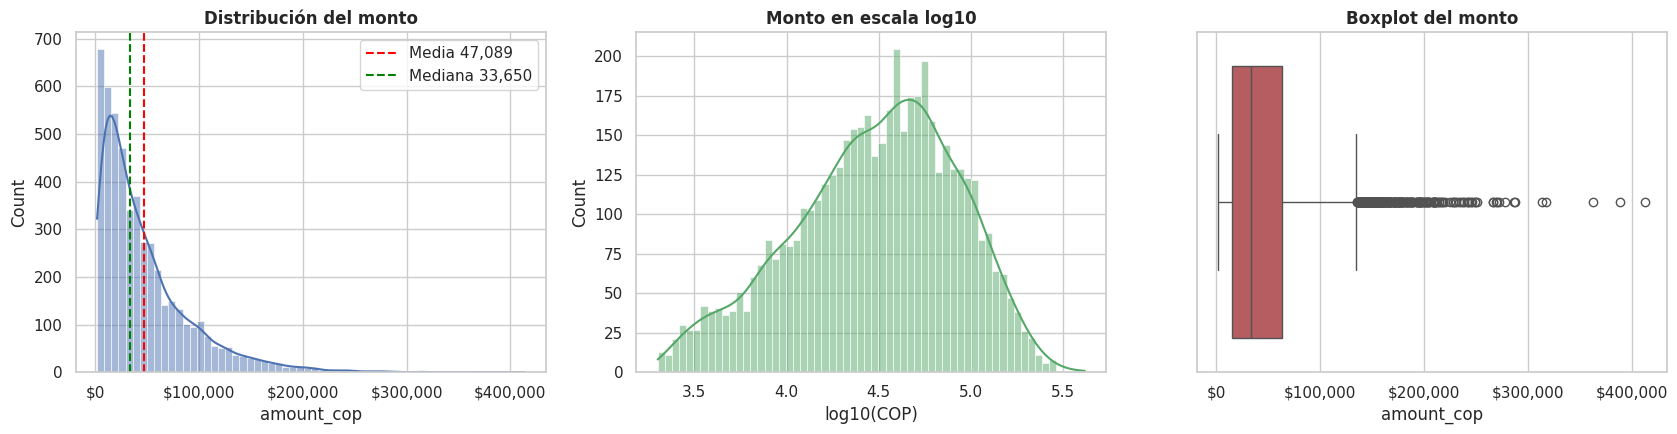

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

sns.histplot(df["amount_cop"], bins=60, kde=True, ax=ax[0], color="#4C72B0")
ax[0].axvline(df["amount_cop"].mean(), color="red", ls="--", label=f"Media {df['amount_cop'].mean():,.0f}")
ax[0].axvline(df["amount_cop"].median(), color="green", ls="--", label=f"Mediana {df['amount_cop'].median():,.0f}")
ax[0].set_title("Distribución del monto"); ax[0].xaxis.set_major_formatter(fmt_cop); ax[0].legend()

sns.histplot(df["log_monto"], bins=60, kde=True, ax=ax[1], color="#55A868")
ax[1].set_title("Monto en escala log10"); ax[1].set_xlabel("log10(COP)")

sns.boxplot(x=df["amount_cop"], ax=ax[2], color="#C44E52")
ax[2].set_title("Boxplot del monto"); ax[2].xaxis.set_major_formatter(fmt_cop)
plt.tight_layout(); plt.show()

In [11]:
# Outliers por regla IQR (1.5 × IQR)
q1, q3 = df["amount_cop"].quantile([.25, .75])
iqr = q3 - q1
lim_sup = q3 + 1.5 * iqr
outliers = df[df["amount_cop"] > lim_sup]
print(f"Límite superior IQR: ${lim_sup:,.0f}")
print(f"Outliers: {len(outliers)} ({len(outliers)/len(df):.2%}) | aportan {outliers['amount_cop'].sum()/df['amount_cop'].sum():.2%} de las ventas")
outliers.sort_values("amount_cop", ascending=False).head(10)[["transaction_id","timestamp","store_id","product_category","amount_cop","payment_method"]]

Límite superior IQR: $135,029
Outliers: 262 (5.24%) | aportan 19.73% de las ventas


,transaction_id,timestamp,store_id,product_category,amount_cop,payment_method
3150,TXN13150,2026-10-04 15:25:21,CAL-01,Granos,413280,Efectivo
2304,TXN12304,2026-09-29 13:52:26,BAR-01,Verduras,389202,Tarjeta
2162,TXN12162,2026-09-28 18:17:28,MED-02,Frutas,362690,Efectivo
523,TXN10523,2026-09-18 14:22:20,MED-01,Snacks,317130,App
1515,TXN11515,2026-09-24 18:57:32,BOG-02,Carnes,313276,App
3861,TXN13861,2026-10-08 21:41:43,BAR-01,Licores,287510,App
3924,TXN13924,2026-10-09 08:51:36,MED-02,Aseo,286344,Tarjeta
2361,TXN12361,2026-09-29 21:21:09,MED-01,Licores,278119,App
191,TXN10191,2026-09-16 14:37:48,BOG-02,Granos,272492,Efectivo
2212,TXN12212,2026-09-29 02:43:51,BAR-01,Carnes,270110,Efectivo


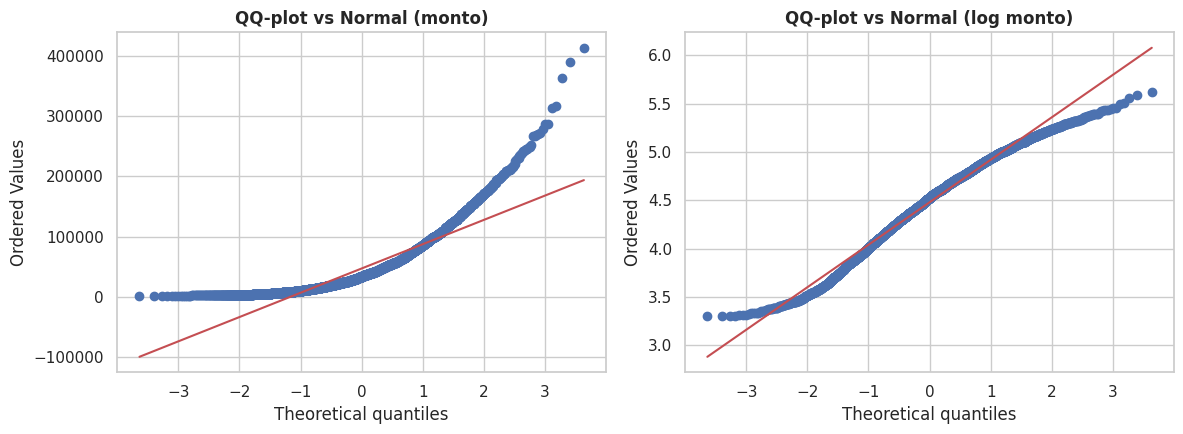

Shapiro (muestra 5000) monto:     p = 1.6953085254662946e-59
Shapiro (muestra 5000) log monto: p = 2.2738862847545358e-23


In [12]:
# ¿El monto sigue una distribución log-normal? (comparación visual con QQ-plot)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
stats.probplot(df["amount_cop"], dist="norm", plot=ax[0]); ax[0].set_title("QQ-plot vs Normal (monto)")
stats.probplot(df["log_monto"], dist="norm", plot=ax[1]); ax[1].set_title("QQ-plot vs Normal (log monto)")
plt.tight_layout(); plt.show()

print("Shapiro (muestra 5000) monto:     p =", stats.shapiro(df["amount_cop"])[1])
print("Shapiro (muestra 5000) log monto: p =", stats.shapiro(df["log_monto"])[1])

### 4.2 Variables categóricas

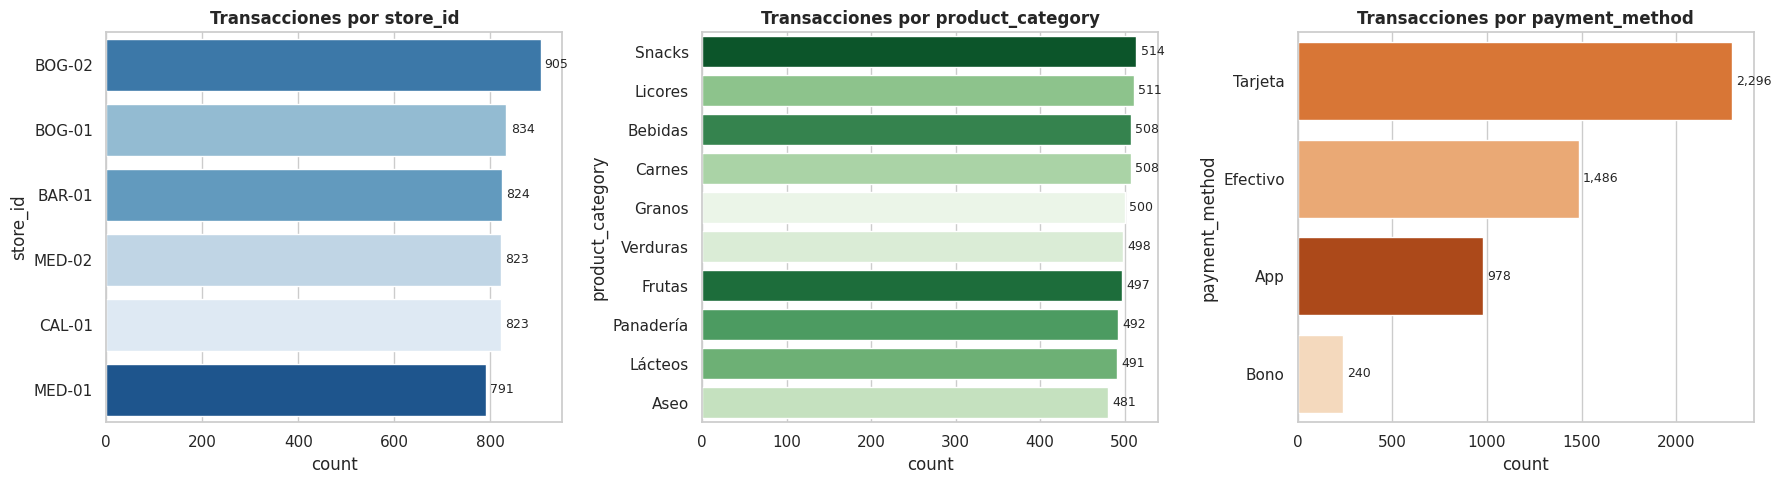

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, c, pal in zip(ax, ["store_id", "product_category", "payment_method"], ["Blues_r", "Greens_r", "Oranges_r"]):
    orden = df[c].value_counts().index
    sns.countplot(data=df, y=c, order=orden, ax=a, palette=pal, hue=c, legend=False)
    a.set_title(f"Transacciones por {c}")
    for p in a.patches:
        a.annotate(f"{int(p.get_width()):,}", (p.get_width(), p.get_y() + p.get_height()/2),
                   va="center", ha="left", fontsize=9, xytext=(3, 0), textcoords="offset points")
plt.tight_layout(); plt.show()

In [14]:
for c in ["store_id", "ciudad", "product_category", "payment_method"]:
    t = df[c].value_counts().to_frame("n")
    t["%"] = t["n"] / t["n"].sum() * 100
    display(t)

,n,%
store_id,,
BOG-02,905,18.10
BOG-01,834,16.68
BAR-01,824,16.48
MED-02,823,16.46
CAL-01,823,16.46
MED-01,791,15.82


,n,%
ciudad,,
Bogotá,1739,34.78
Medellín,1614,32.28
Barranquilla,824,16.48
Cali,823,16.46


,n,%
product_category,,
Snacks,514,10.28
Licores,511,10.22
Bebidas,508,10.16
Carnes,508,10.16
Granos,500,10.00
Verduras,498,9.96
Frutas,497,9.94
Panadería,492,9.84
Lácteos,491,9.82


,n,%
payment_method,,
Tarjeta,2296,45.92
Efectivo,1486,29.72
App,978,19.56
Bono,240,4.80


In [15]:
# ¿Las categorías están balanceadas? Chi-cuadrado contra distribución uniforme
for c in ["store_id", "product_category", "payment_method"]:
    chi, p = stats.chisquare(df[c].value_counts())
    print(f"{c:18s} χ²={chi:8.2f}  p={p:.4f}  →", "NO uniforme" if p < 0.05 else "compatible con uniforme")

store_id           χ²=    8.68  p=0.1227  → compatible con uniforme
product_category   χ²=    1.93  p=0.9926  → compatible con uniforme
payment_method     χ²= 1795.12  p=0.0000  → NO uniforme


## 5. Análisis bivariado

### 5.1 Monto por categoría de producto

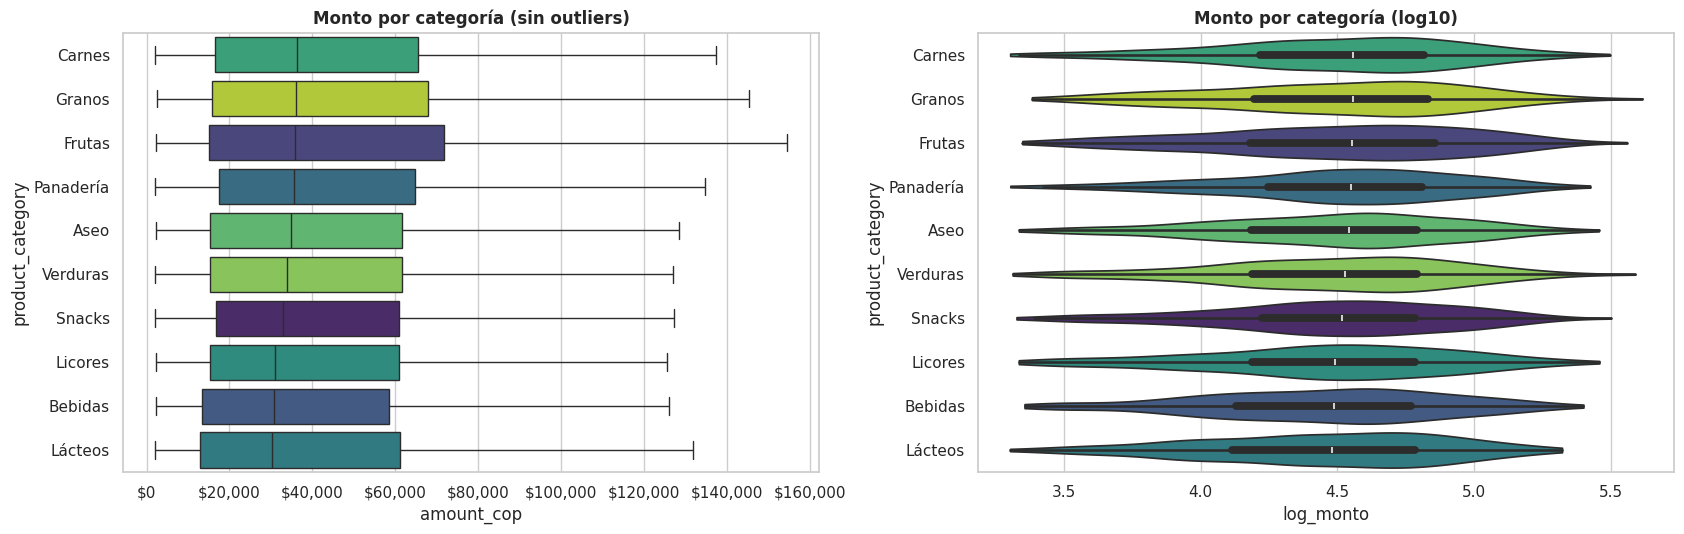

,transacciones,ventas,ticket_medio,mediana,p90
product_category,,,,,
Frutas,497,25187823,"50,679.72","35,727.00","120,157.00"
Granos,500,24851183,"49,702.37","35,986.00","111,084.70"
Carnes,508,24847388,"48,912.18","36,181.00","107,808.60"
Panadería,492,23764186,"48,301.19","35,590.00","109,396.40"
Licores,511,23754897,"46,487.08","30,924.00","102,988.00"
Snacks,514,23560518,"45,837.58","32,802.00","101,876.40"
Verduras,498,23267866,"46,722.62","33,856.50","102,325.40"
Aseo,481,22557725,"46,897.56","34,774.00","103,594.00"
Bebidas,508,22446974,"44,186.96","30,828.00","102,444.30"


In [16]:
orden = df.groupby("product_category")["amount_cop"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(1, 2, figsize=(17, 5.5))
sns.boxplot(data=df, y="product_category", x="amount_cop", order=orden, ax=ax[0], showfliers=False, palette="viridis", hue="product_category", legend=False)
ax[0].set_title("Monto por categoría (sin outliers)"); ax[0].xaxis.set_major_formatter(fmt_cop)
sns.violinplot(data=df, y="product_category", x="log_monto", order=orden, ax=ax[1], palette="viridis", hue="product_category", legend=False, cut=0)
ax[1].set_title("Monto por categoría (log10)")
plt.tight_layout(); plt.show()

(df.groupby("product_category")["amount_cop"]
   .agg(transacciones="count", ventas="sum", ticket_medio="mean", mediana="median", p90=lambda s: s.quantile(.9))
   .sort_values("ventas", ascending=False))

### 5.2 Ventas por tienda y ciudad

,,transacciones,ventas,ticket_medio,mediana,% ventas
ciudad,store_id,,,,,
Bogotá,BOG-02,905,44284830,"48,933.51","34,396.00",18.81
Medellín,MED-02,823,40139777,"48,772.51","36,737.00",17.05
Bogotá,BOG-01,834,39170054,"46,966.49","35,213.00",16.64
Barranquilla,BAR-01,824,38470367,"46,687.34","35,222.00",16.34
Cali,CAL-01,823,38039308,"46,220.30","31,026.00",16.16
Medellín,MED-01,791,35340730,"44,678.55","29,402.00",15.01


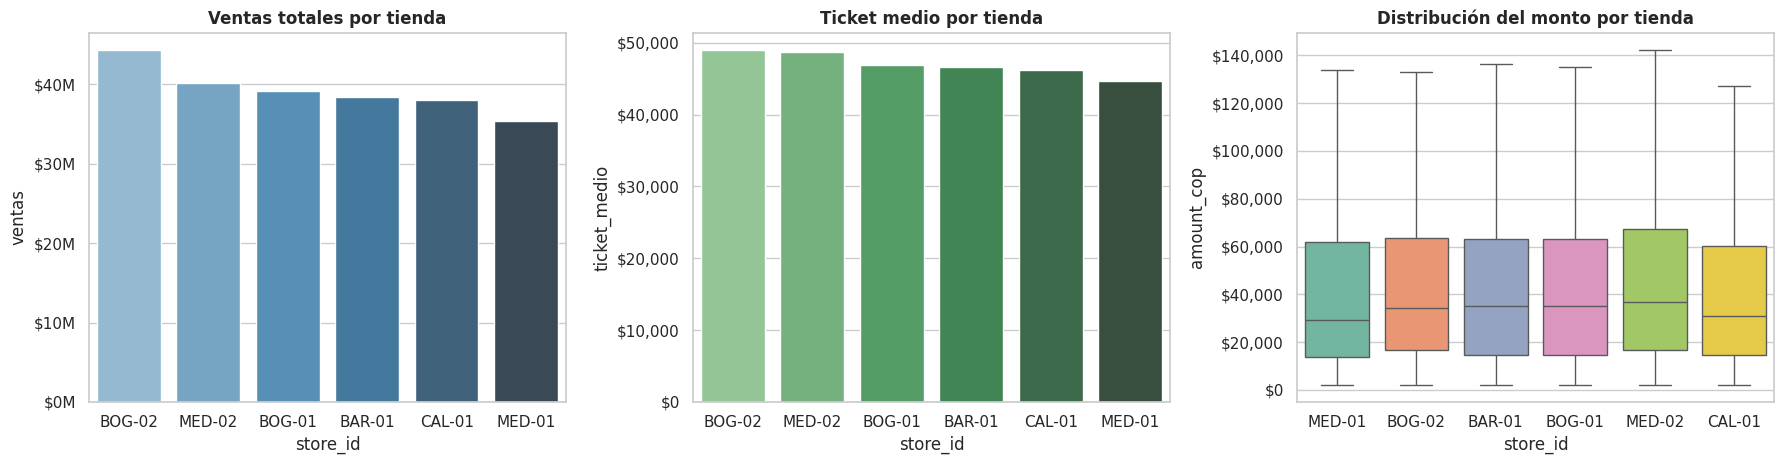

In [17]:
por_tienda = (df.groupby(["ciudad", "store_id"])["amount_cop"]
                .agg(transacciones="count", ventas="sum", ticket_medio="mean", mediana="median")
                .sort_values("ventas", ascending=False))
por_tienda["% ventas"] = por_tienda["ventas"] / por_tienda["ventas"].sum() * 100
display(por_tienda)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
v = por_tienda.reset_index()
sns.barplot(data=v, x="store_id", y="ventas", ax=ax[0], palette="Blues_d", hue="store_id", legend=False)
ax[0].set_title("Ventas totales por tienda"); ax[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x,_: f"${x/1e6:,.0f}M"))
sns.barplot(data=v, x="store_id", y="ticket_medio", ax=ax[1], palette="Greens_d", hue="store_id", legend=False)
ax[1].set_title("Ticket medio por tienda"); ax[1].yaxis.set_major_formatter(fmt_cop)
sns.boxplot(data=df, x="store_id", y="amount_cop", ax=ax[2], showfliers=False, palette="Set2", hue="store_id", legend=False)
ax[2].set_title("Distribución del monto por tienda"); ax[2].yaxis.set_major_formatter(fmt_cop)
plt.tight_layout(); plt.show()

### 5.3 Método de pago

,transacciones,ventas,ticket_medio,mediana,% transacciones,% ventas
payment_method,,,,,,
Tarjeta,2296,107047299,"46,623.39","33,072.50",45.92,45.47
Efectivo,1486,70127784,"47,192.32","33,785.00",29.72,29.79
App,978,47059223,"48,117.81","35,381.50",19.56,19.99
Bono,240,11210760,"46,711.50","32,100.50",4.80,4.76


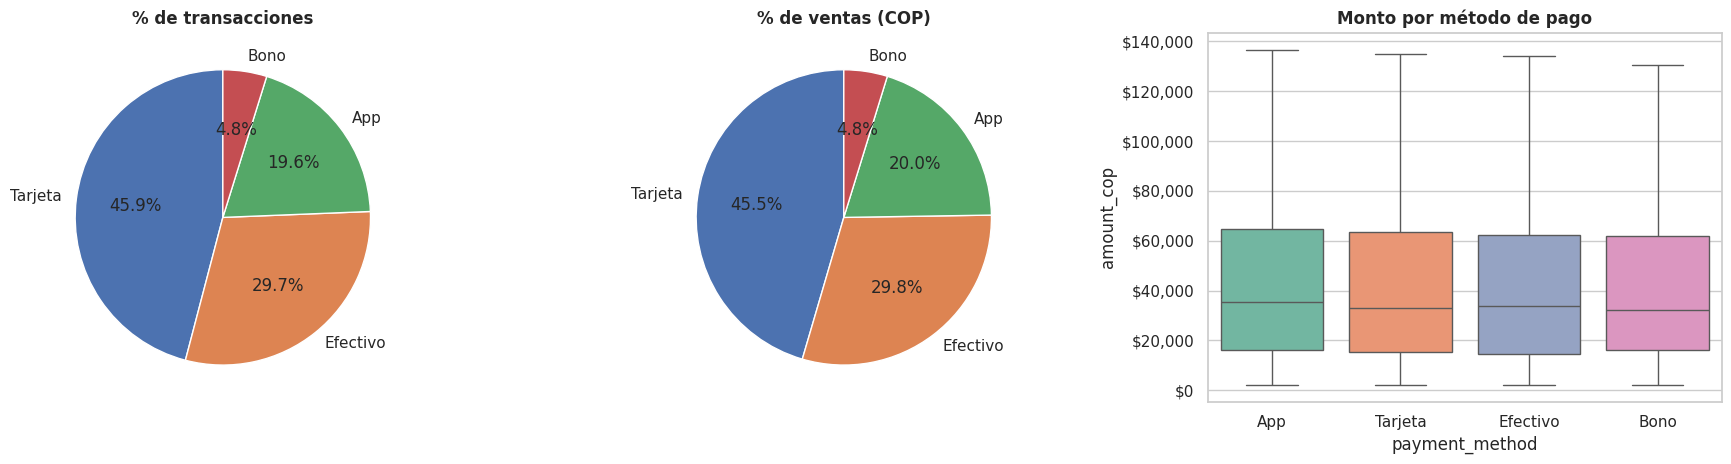

In [18]:
mp = (df.groupby("payment_method")["amount_cop"]
        .agg(transacciones="count", ventas="sum", ticket_medio="mean", mediana="median")
        .sort_values("ventas", ascending=False))
mp["% transacciones"] = mp["transacciones"] / mp["transacciones"].sum() * 100
mp["% ventas"] = mp["ventas"] / mp["ventas"].sum() * 100
display(mp)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
df["payment_method"].value_counts().plot.pie(autopct="%1.1f%%", ax=ax[0], startangle=90, ylabel="")
ax[0].set_title("% de transacciones")
mp["ventas"].plot.pie(autopct="%1.1f%%", ax=ax[1], startangle=90, ylabel="")
ax[1].set_title("% de ventas (COP)")
sns.boxplot(data=df, x="payment_method", y="amount_cop", ax=ax[2], showfliers=False, palette="Set2", hue="payment_method", legend=False)
ax[2].set_title("Monto por método de pago"); ax[2].yaxis.set_major_formatter(fmt_cop)
plt.tight_layout(); plt.show()

## 6. Patrones temporales

Días con datos: 31
⚠ Primer día (parcial) empieza a las 08:02:06 | último día (parcial) termina a las 17:59:48


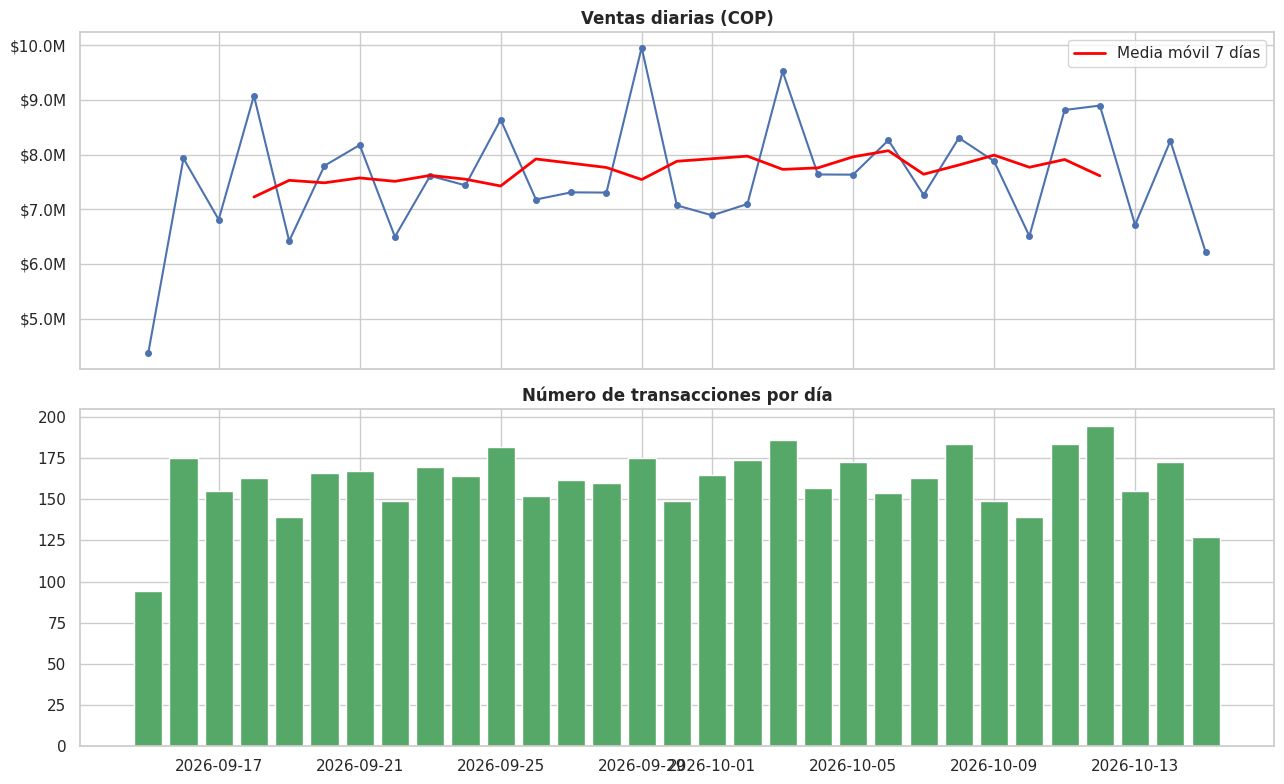

In [19]:
diario = df.groupby("fecha").agg(transacciones=("amount_cop", "size"), ventas=("amount_cop", "sum"), ticket=("amount_cop", "mean"))
print("Días con datos:", len(diario))
print("⚠ Primer día (parcial) empieza a las", df['timestamp'].min().time(), "| último día (parcial) termina a las", df['timestamp'].max().time())

fig, ax = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
ax[0].plot(diario.index, diario["ventas"], marker="o", ms=4, color="#4C72B0")
ax[0].plot(diario["ventas"].rolling(7, center=True).mean(), color="red", lw=2, label="Media móvil 7 días")
ax[0].set_title("Ventas diarias (COP)"); ax[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x,_: f"${x/1e6:,.1f}M")); ax[0].legend()
ax[1].bar(diario.index, diario["transacciones"], color="#55A868")
ax[1].set_title("Número de transacciones por día")
plt.tight_layout(); plt.show()

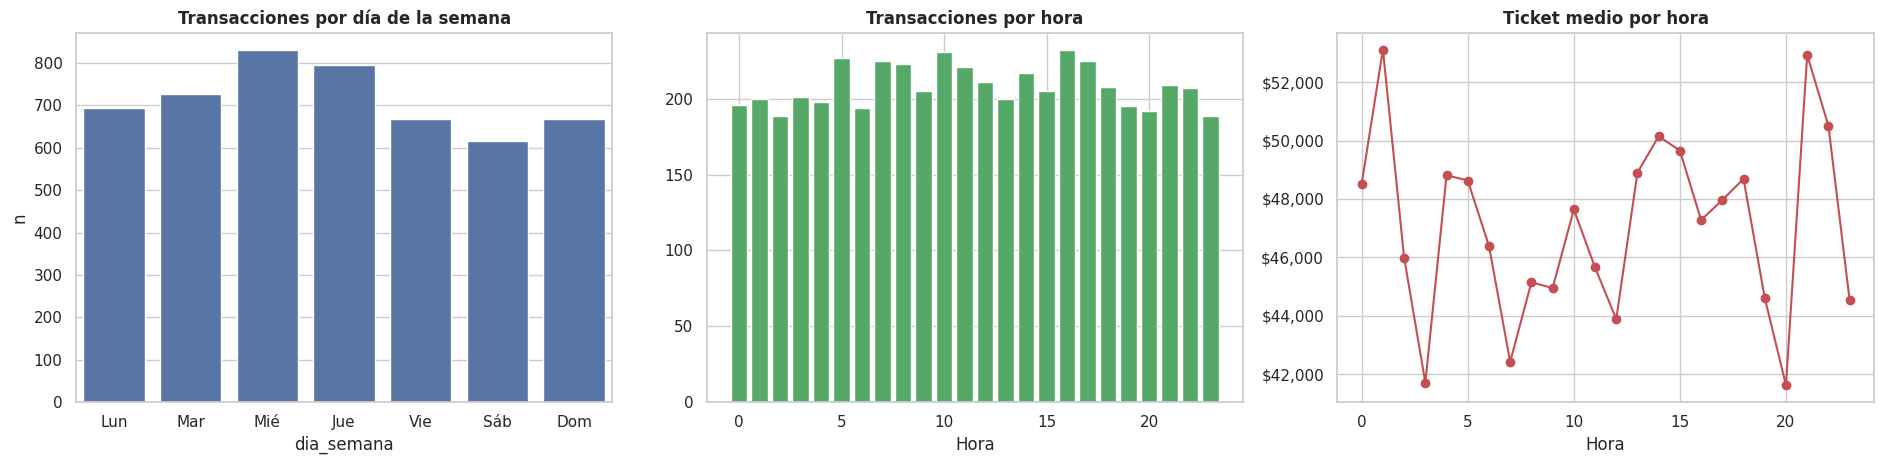

,n,ventas,ticket
dia_semana,,,
Lun,695,32006408,"46,052.39"
Mar,727,35793192,"49,234.10"
Mié,830,38120790,"45,928.66"
Jue,795,35659099,"44,854.21"
Vie,668,32686188,"48,931.42"
Sáb,616,29625776,"48,093.79"
Dom,669,31553613,"47,165.34"


In [20]:
# Día de la semana y hora del día
fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))

dow = df.groupby("dia_semana", observed=True).agg(n=("amount_cop","size"), ventas=("amount_cop","sum"), ticket=("amount_cop","mean"))
sns.barplot(x=dow.index, y=dow["n"], ax=ax[0], color="#4C72B0"); ax[0].set_title("Transacciones por día de la semana")

h = df.groupby("hora").agg(n=("amount_cop","size"), ticket=("amount_cop","mean"))
ax[1].bar(h.index, h["n"], color="#55A868"); ax[1].set_title("Transacciones por hora"); ax[1].set_xlabel("Hora")
ax[2].plot(h.index, h["ticket"], marker="o", color="#C44E52"); ax[2].set_title("Ticket medio por hora")
ax[2].yaxis.set_major_formatter(fmt_cop); ax[2].set_xlabel("Hora")
plt.tight_layout(); plt.show()
dow

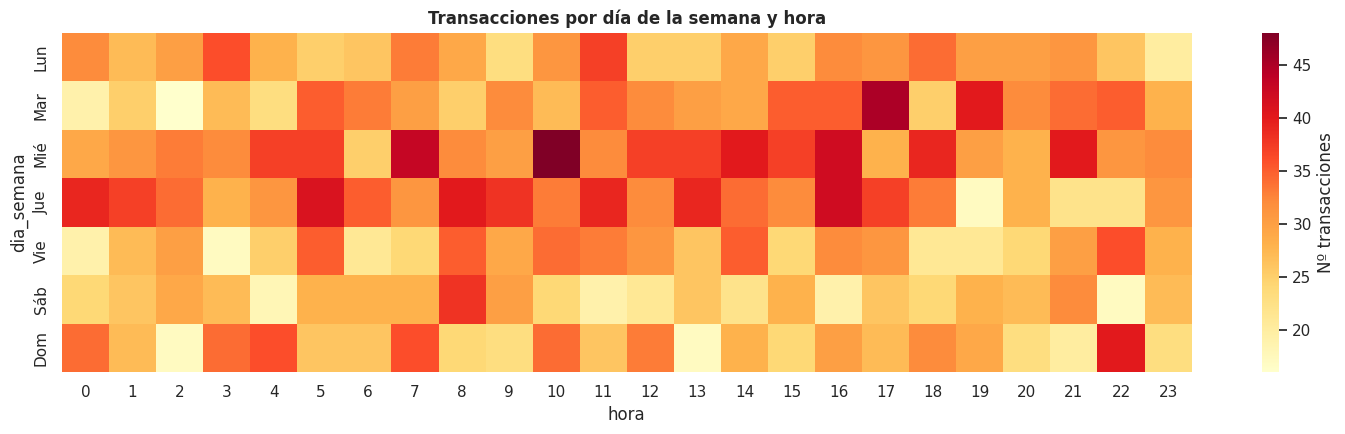

In [21]:
# Mapa de calor día × hora
heat = df.pivot_table(index="dia_semana", columns="hora", values="amount_cop", aggfunc="size", observed=True)
plt.figure(figsize=(15, 4.5))
sns.heatmap(heat, cmap="YlOrRd", annot=False, cbar_kws={"label": "Nº transacciones"})
plt.title("Transacciones por día de la semana y hora"); plt.tight_layout(); plt.show()

In [22]:
# Ventas semanales y por franja horaria
sem = df.groupby("semana").agg(n=("amount_cop","size"), ventas=("amount_cop","sum"))
display(sem)

fr = df.groupby("franja", observed=True).agg(n=("amount_cop","size"), ventas=("amount_cop","sum"), ticket=("amount_cop","mean"))
fr["% ventas"] = fr["ventas"] / fr["ventas"].sum() * 100
fr

,n,ventas
semana,,
2026-09-14,892,42393833
2026-09-21,1146,52843885
2026-09-28,1166,55468500
2026-10-05,1146,54660054
2026-10-12,650,30078794


,n,ventas,ticket,% ventas
franja,,,,
Madrugada (0-5),1211,57913075,"47,822.52",24.60
Mañana (6-11),1299,58918220,"45,356.60",25.02
Tarde (12-17),1290,61860187,"47,953.63",26.27
Noche (18-23),1200,56753584,"47,294.65",24.10


## 7. Cruces entre variables y pruebas estadísticas

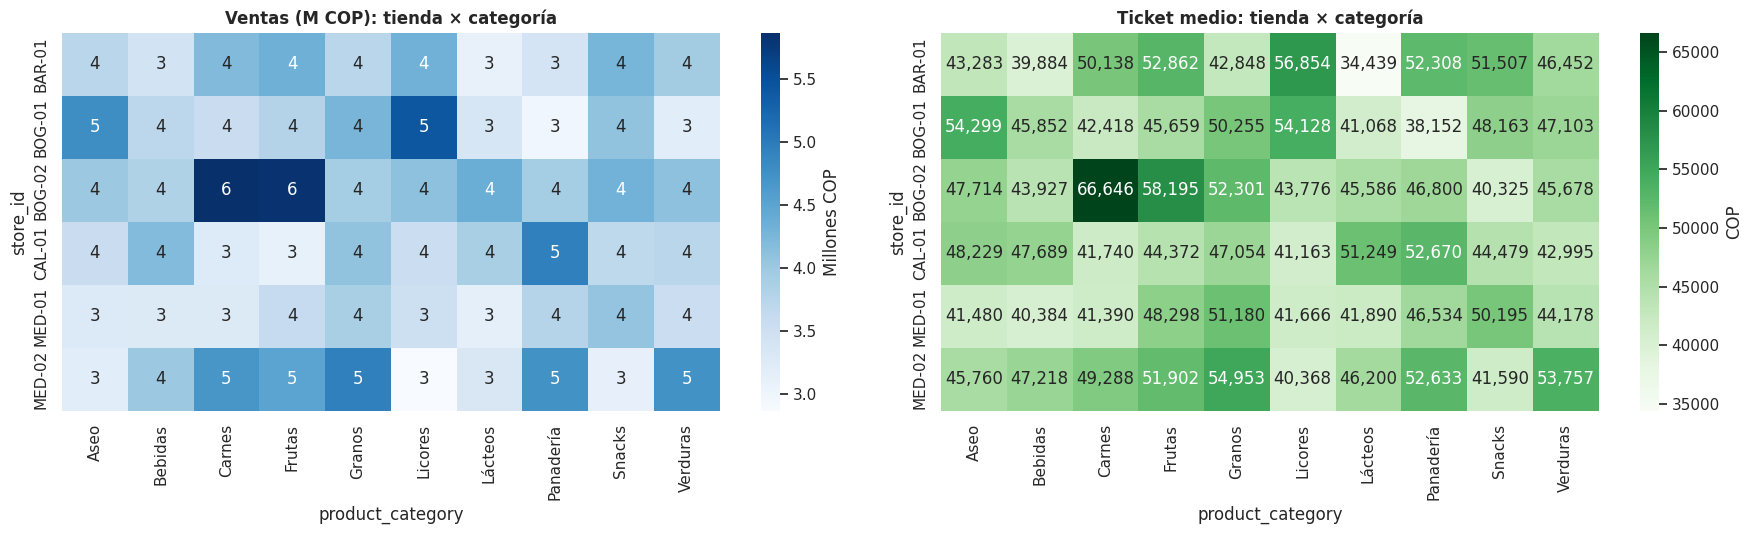

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(18, 5.5))
pv = df.pivot_table(index="store_id", columns="product_category", values="amount_cop", aggfunc="sum") / 1e6
sns.heatmap(pv, annot=True, fmt=".0f", cmap="Blues", ax=ax[0], cbar_kws={"label": "Millones COP"})
ax[0].set_title("Ventas (M COP): tienda × categoría")

pt = df.pivot_table(index="store_id", columns="product_category", values="amount_cop", aggfunc="mean")
sns.heatmap(pt, annot=True, fmt=",.0f", cmap="Greens", ax=ax[1], cbar_kws={"label": "COP"})
ax[1].set_title("Ticket medio: tienda × categoría")
plt.tight_layout(); plt.show()

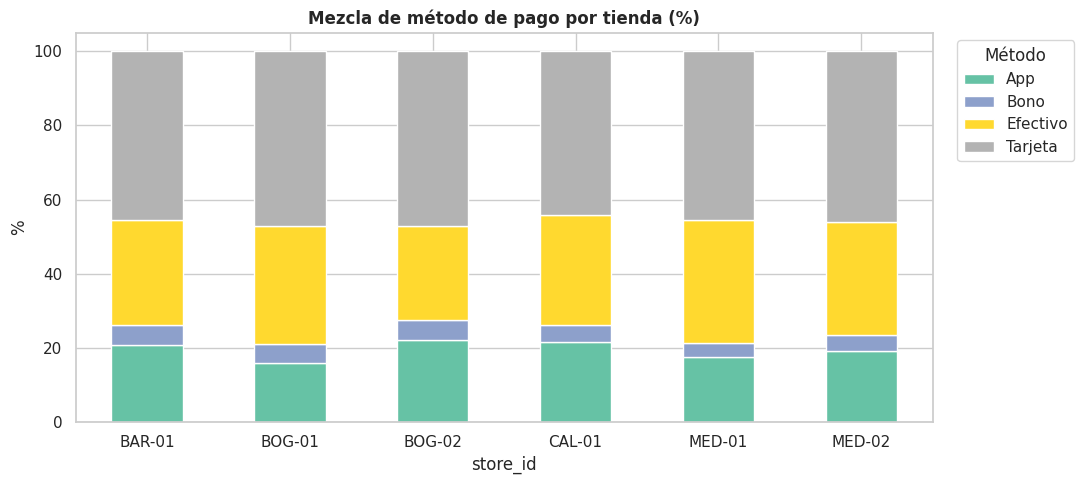

payment_method,App,Bono,Efectivo,Tarjeta
store_id,,,,
BAR-01,20.87,5.34,28.40,45.39
BOG-01,15.95,5.04,32.01,47.00
BOG-02,21.99,5.52,25.41,47.07
CAL-01,21.63,4.50,29.65,44.23
MED-01,17.57,3.79,33.12,45.51
MED-02,19.08,4.50,30.26,46.17


In [24]:
# Método de pago por tienda (% por fila)
ct = pd.crosstab(df["store_id"], df["payment_method"], normalize="index") * 100
ax = ct.plot.bar(stacked=True, figsize=(11, 5), colormap="Set2")
ax.set_title("Mezcla de método de pago por tienda (%)"); ax.set_ylabel("%"); plt.xticks(rotation=0)
plt.legend(title="Método", bbox_to_anchor=(1.02, 1)); plt.tight_layout(); plt.show()
ct

In [25]:
# Pruebas de hipótesis
print("── ¿Hay asociación entre variables categóricas? (Chi-cuadrado de independencia) ──")
for a, b in [("store_id","product_category"), ("store_id","payment_method"), ("product_category","payment_method")]:
    chi, p, dof, _ = stats.chi2_contingency(pd.crosstab(df[a], df[b]))
    print(f"{a:18s} × {b:18s} χ²={chi:7.1f} gl={dof:3d} p={p:.4f} →", "asociadas" if p < .05 else "independientes")

print("\n── ¿El monto difiere entre grupos? (Kruskal-Wallis, no paramétrico) ──")
for c in ["store_id", "product_category", "payment_method", "dia_semana", "franja"]:
    grupos = [g["amount_cop"].values for _, g in df.groupby(c, observed=True)]
    h, p = stats.kruskal(*grupos)
    print(f"{c:18s} H={h:7.2f} p={p:.4f} →", "difiere" if p < .05 else "sin diferencia significativa")

print("\n── Fin de semana vs entre semana (Mann-Whitney) ──")
u, p = stats.mannwhitneyu(df.loc[df.es_fin_semana, "amount_cop"], df.loc[~df.es_fin_semana, "amount_cop"])
print(f"p={p:.4f}")

── ¿Hay asociación entre variables categóricas? (Chi-cuadrado de independencia) ──
store_id           × product_category   χ²=   35.5 gl= 45 p=0.8441 → independientes
store_id           × payment_method     χ²=   27.9 gl= 15 p=0.0219 → asociadas
product_category   × payment_method     χ²=   28.9 gl= 27 p=0.3655 → independientes

── ¿El monto difiere entre grupos? (Kruskal-Wallis, no paramétrico) ──
store_id           H=  10.81 p=0.0554 → sin diferencia significativa
product_category   H=  11.11 p=0.2684 → sin diferencia significativa
payment_method     H=   1.05 p=0.7891 → sin diferencia significativa
dia_semana         H=   3.81 p=0.7020 → sin diferencia significativa
franja             H=   0.27 p=0.9657 → sin diferencia significativa

── Fin de semana vs entre semana (Mann-Whitney) ──
p=0.6213


## 8. Conclusiones de la Parte 1

> Los hallazgos de abajo corresponden a la ejecución sobre este archivo; si cambias los datos, vuelve a revisarlos.

### Calidad de datos
- **Muy limpio:** 5.000 filas, 0 nulos, 0 IDs duplicados, 0 montos ≤ 0, categorías consistentes (6 tiendas, 10 categorías, 4 métodos de pago).
- Hay **5 timestamps repetidos** (pares de transacciones en el mismo segundo, en tiendas/categorías distintas): son plausibles, no errores.
- **Cobertura temporal:** 15-sep-2026 a 15-oct-2026 (31 días). El primer y el último día son parciales (08:02 y 17:59), por lo que no conviene compararlos con días completos.
- **Dato llamativo:** hay transacciones a **todas las horas del día**, incluida la madrugada (~24 % de las ventas entre 0 y 5 h), con una distribución casi plana. Es raro para comercio físico; conviene confirmar si los `timestamp` están en UTC, si hay ventas 24/7 o si es una variable generada/sintética.

### Monto (`amount_cop`)
- Ventas totales ≈ **$235,4 M COP**; ticket medio **$47.089**, mediana **$33.650**.
- Distribución **asimétrica a la derecha** (asimetría 1,93; CV 0,94): la media supera a la mediana y no es normal ni log-normal exacta (Shapiro rechaza ambas), aunque el log acerca mucho la forma.
- El **5,2 % de las transacciones** supera el límite IQR ($135.029) y concentra el **19,7 % de las ventas**. Máximo: $413.280. No parecen errores sino compras grandes, pero vale la pena revisarlas.

### Tiendas, categorías y pagos
- **Tiendas:** BOG-02 lidera (905 trans., 18,8 % de ventas) y MED-01 es la más baja (791, 15,0 %). Aun así, el reparto de transacciones entre tiendas es compatible con uniforme (p = 0,12) y el monto no difiere de forma significativa (Kruskal p = 0,055, en el límite).
- **Categorías:** prácticamente balanceadas (~10 % cada una). Frutas, Granos y Carnes lideran en ventas; Lácteos y Bebidas tienen el ticket más bajo, pero las diferencias de monto **no son significativas** (p = 0,27).
- **Método de pago:** el único desbalanceado: Tarjeta 45,9 %, Efectivo 29,7 %, App 19,6 %, Bono 4,8 %. El ticket es similar entre métodos (p = 0,79), y el % de ventas casi coincide con el % de transacciones.
- La mezcla de pagos **sí varía por tienda** (χ² p = 0,02): p. ej. BOG-02 y CAL-01 usan más App (~22 %), mientras BOG-01 y MED-01 tienen más efectivo (~32-33 %).

### Tiempo
- Volumen diario estable (~150-190 transacciones en días completos), sin tendencia clara.
- Entre semana vs fin de semana no hay diferencia de monto (p = 0,62). Miércoles es el día con más transacciones (830) y sábado el menor (616), pero la diferencia en monto por día no es significativa.
- No hay franja horaria dominante: las cuatro franjas aportan entre 24 % y 26 % de las ventas.

### Lectura general y siguientes pasos
Los datos están limpios pero muestran **poca estructura**: casi todas las variables son estadísticamente independientes entre sí, con las excepciones de la mezcla de pago por tienda y un posible efecto tienda sobre el monto. Esto, junto con la actividad 24 h, sugiere que podrían ser datos simulados. Pasos recomendados:
1. Confirmar la zona horaria y el horario real de operación de las tiendas.
2. Investigar las compras > $135 mil (¿mayoristas, errores de digitación?).
3. Añadir datos de cliente, producto/SKU y cantidades para poder segmentar y modelar (RFM, canasta, pronóstico de demanda).
4. Si hay más de un mes de historia, repetir el análisis para ver estacionalidad (quincena, fin de mes, festivos).

---
# PARTE 2 — Logs de e-commerce (JSON)

Eventos de navegación y compra: `event_id`, `timestamp`, `user_id`, `event_type`, `device`, `product_category`, `session_duration_sec`.

## 9. Carga y calidad de datos

In [26]:
logs = pd.read_json("ecommerce_logs_5000.json")

# El timestamp viene en UTC (sufijo "Z"); lo dejamos como fecha-hora UTC sin zona para poder compararlo con el POS
logs["timestamp"] = pd.to_datetime(logs["timestamp"], utc=True).dt.tz_localize(None)

print(f"Filas: {len(logs):,} | Columnas: {logs.shape[1]}")
logs.head(10)

Filas: 5,000 | Columnas: 7


,event_id,timestamp,user_id,event_type,device,product_category,session_duration_sec
0,evt_00001,2026-09-06 14:23:05,usr_1505,purchase,mobile,beauty,1170
1,evt_00002,2026-08-08 06:16:21,usr_3992,search,tablet,sports,46
2,evt_00003,2026-07-04 00:59:11,usr_6587,add_to_cart,tablet,clothing,497
3,evt_00004,2026-12-14 23:17:40,usr_8585,checkout_start,mobile,electronics,103
4,evt_00005,2026-02-10 16:46:38,usr_1972,checkout_start,mobile,electronics,1491
5,evt_00006,2026-03-11 21:07:20,usr_9346,search,mobile,home,500
6,evt_00007,2026-05-07 15:14:35,usr_5567,page_view,tablet,home,1437
7,evt_00008,2026-09-15 07:49:19,usr_1120,remove_from_cart,mobile,electronics,1287
8,evt_00009,2026-12-19 22:12:10,usr_9504,checkout_start,mobile,clothing,466
9,evt_00010,2026-10-26 18:25:12,usr_4778,checkout_start,desktop,home,1653


In [27]:
logs.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   event_id              5000 non-null   str           
 1   timestamp             5000 non-null   datetime64[us]
 2   user_id               5000 non-null   str           
 3   event_type            5000 non-null   str           
 4   device                5000 non-null   str           
 5   product_category      5000 non-null   str           
 6   session_duration_sec  5000 non-null   int64         
dtypes: datetime64[us](1), int64(1), str(5)
memory usage: 273.6 KB


In [28]:
calidad_logs = pd.DataFrame({"nulos": logs.isna().sum(), "únicos": logs.nunique()})
display(calidad_logs)

print("event_id duplicados:        ", logs["event_id"].duplicated().sum())
print("Filas duplicadas completas: ", logs.duplicated().sum())
print("Formato event_id (evt_#####):", logs["event_id"].str.fullmatch(r"evt_\d{5}").all())
print("Formato user_id (usr_####):  ", logs["user_id"].str.fullmatch(r"usr_\d{4}").all())
print("Duración <= 0:              ", (logs["session_duration_sec"] <= 0).sum())
print("Rango de fechas:", logs["timestamp"].min(), "→", logs["timestamp"].max())
print("Ordenado cronológicamente:  ", logs["timestamp"].is_monotonic_increasing,
      "(el archivo viene ordenado por event_id, no por fecha)")
for c in ["event_type", "device", "product_category"]:
    print(f"{c:17s}", sorted(logs[c].unique()))

,nulos,únicos
event_id,0,5000
timestamp,0,5000
user_id,0,3792
event_type,0,6
device,0,3
product_category,0,5
session_duration_sec,0,1684


event_id duplicados:         0
Filas duplicadas completas:  0
Formato event_id (evt_#####): True
Formato user_id (usr_####):   True
Duración <= 0:               0
Rango de fechas: 2026-01-01 00:17:38 → 2026-12-31 23:54:45
Ordenado cronológicamente:   False (el archivo viene ordenado por event_id, no por fecha)
event_type        ['add_to_cart', 'checkout_start', 'page_view', 'purchase', 'remove_from_cart', 'search']
device            ['desktop', 'mobile', 'tablet']
product_category  ['beauty', 'clothing', 'electronics', 'home', 'sports']


Último registro POS (corte): 2026-10-15 17:59:48
Eventos posteriores al corte: 1,066 (21.3%)


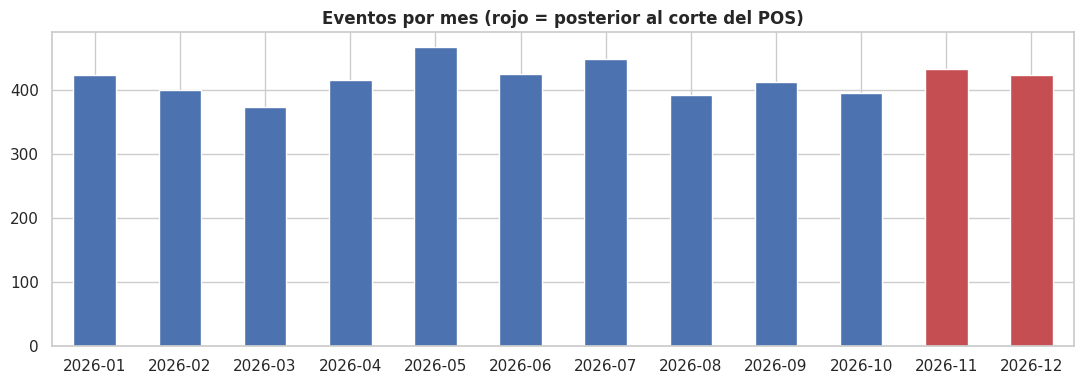

In [29]:
# ¿Hay eventos posteriores al último registro del POS?  (corte = última transacción del CSV)
corte_pos = df["timestamp"].max()
futuros = logs["timestamp"] > corte_pos
print(f"Último registro POS (corte): {corte_pos}")
print(f"Eventos posteriores al corte: {futuros.sum():,} ({futuros.mean():.1%})")

mensual = logs.groupby(logs["timestamp"].dt.to_period("M")).size()
colores = ["#C44E52" if p.start_time > corte_pos else "#4C72B0" for p in mensual.index]
ax = mensual.plot.bar(color=colores, figsize=(11, 4)); ax.set_title("Eventos por mes (rojo = posterior al corte del POS)")
ax.set_xlabel(""); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 10. Variables derivadas

In [30]:
orden_eventos = ["page_view", "search", "add_to_cart", "remove_from_cart", "checkout_start", "purchase"]
etapas_embudo = ["page_view", "search", "add_to_cart", "checkout_start", "purchase"]

logs = logs.sort_values("timestamp").reset_index(drop=True)
logs["event_type"] = pd.Categorical(logs["event_type"], categories=orden_eventos, ordered=True)
logs["fecha"] = logs["timestamp"].dt.normalize()
logs["mes"] = logs["timestamp"].dt.to_period("M").astype(str)
logs["hora"] = logs["timestamp"].dt.hour
logs["dia_semana"] = pd.Categorical(logs["timestamp"].dt.dayofweek.map(dias_es), categories=orden_dias, ordered=True)
logs["es_compra"] = logs["event_type"] == "purchase"
logs[["timestamp", "user_id", "event_type", "device", "product_category", "session_duration_sec", "hora", "dia_semana"]].head()

,timestamp,user_id,event_type,device,product_category,session_duration_sec,hora,dia_semana
0,2026-01-01 00:17:38,usr_7843,add_to_cart,desktop,beauty,965,0,Jue
1,2026-01-01 01:16:14,usr_3234,purchase,desktop,home,1785,1,Jue
2,2026-01-01 01:39:33,usr_9350,checkout_start,mobile,electronics,1438,1,Jue
3,2026-01-01 05:47:29,usr_7033,checkout_start,mobile,sports,747,5,Jue
4,2026-01-01 07:24:15,usr_5568,remove_from_cart,mobile,beauty,1080,7,Jue


## 11. Análisis univariado

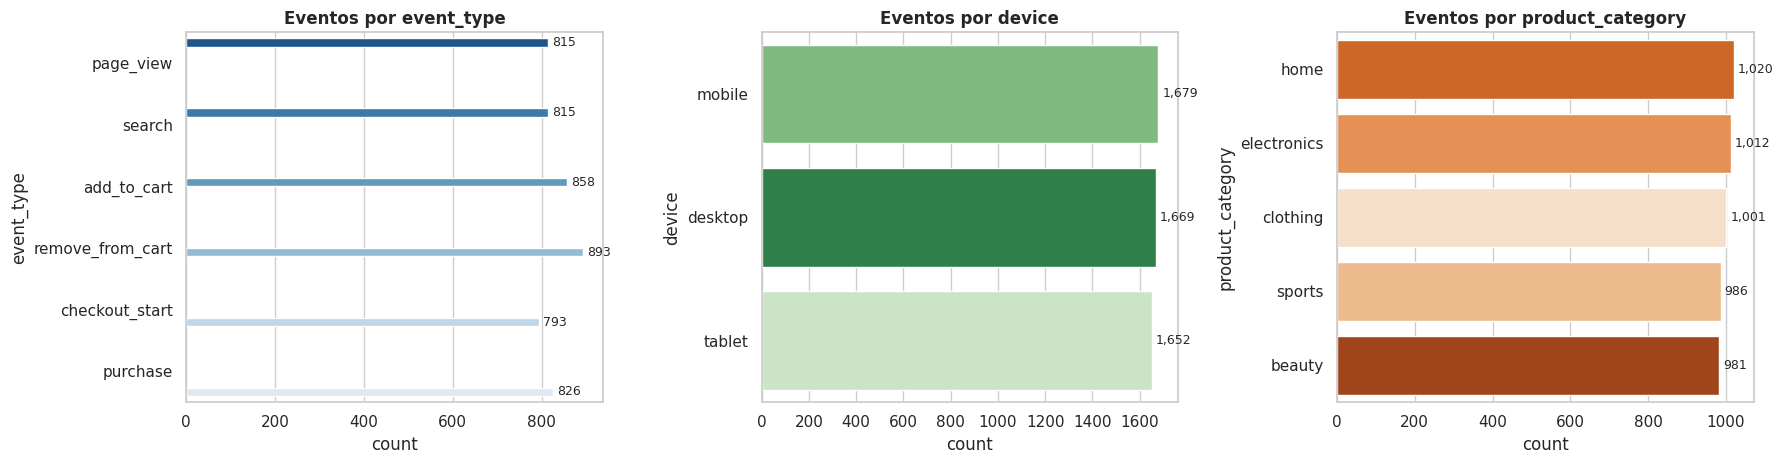

¿Distribución uniforme? (chi-cuadrado)
  event_type        χ²=  7.83  p=0.1661 → compatible con uniforme
  device            χ²=  0.22  p=0.8942 → compatible con uniforme
  product_category  χ²=  1.10  p=0.8940 → compatible con uniforme


In [31]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
for a, c, pal in zip(ax, ["event_type", "device", "product_category"], ["Blues_r", "Greens_r", "Oranges_r"]):
    orden = orden_eventos if c == "event_type" else logs[c].value_counts().index
    sns.countplot(data=logs, y=c, order=orden, ax=a, palette=pal, hue=c, legend=False)
    a.set_title(f"Eventos por {c}")
    for p in a.patches:
        a.annotate(f"{int(p.get_width()):,}", (p.get_width(), p.get_y() + p.get_height()/2),
                   va="center", ha="left", fontsize=9, xytext=(3, 0), textcoords="offset points")
plt.tight_layout(); plt.show()

print("¿Distribución uniforme? (chi-cuadrado)")
for c in ["event_type", "device", "product_category"]:
    chi, p = stats.chisquare(logs[c].value_counts())
    print(f"  {c:17s} χ²={chi:6.2f}  p={p:.4f} →", "NO uniforme" if p < .05 else "compatible con uniforme")

,session_duration_sec
count,"5,000.00"
mean,892.13
std,518.50
min,10.00
10%,188.00
25%,448.00
50%,874.50
75%,"1,335.00"
90%,"1,620.00"
max,"1,800.00"


Asimetría: 0.057


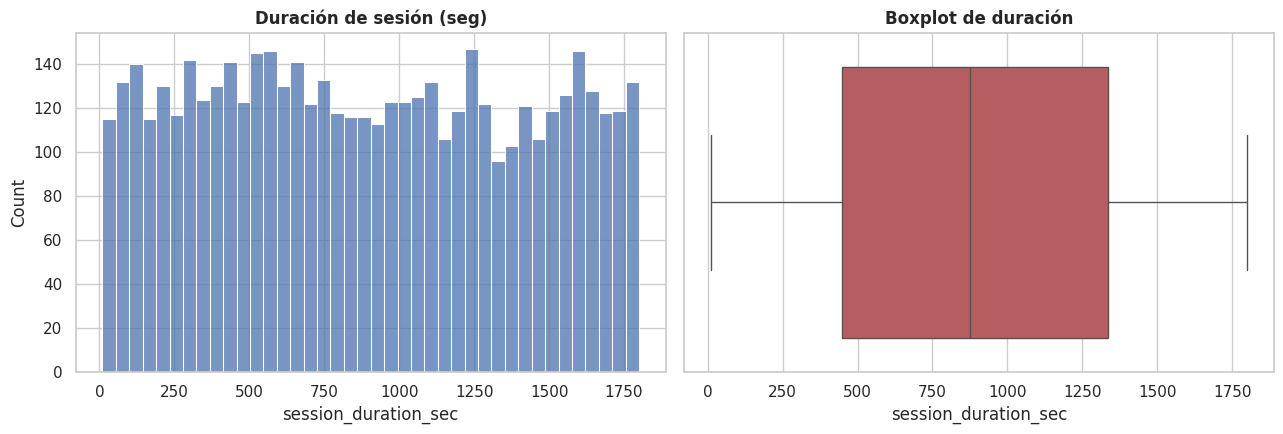

KS vs uniforme[10, 1800]: D=0.0210  p=0.0243


In [32]:
display(logs["session_duration_sec"].describe(percentiles=[.1, .25, .5, .75, .9]).to_frame())
print("Asimetría:", round(logs["session_duration_sec"].skew(), 3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(logs["session_duration_sec"], bins=40, ax=ax[0], color="#4C72B0")
ax[0].set_title("Duración de sesión (seg)")
sns.boxplot(x=logs["session_duration_sec"], ax=ax[1], color="#C44E52"); ax[1].set_title("Boxplot de duración")
plt.tight_layout(); plt.show()

# ¿La duración se parece a una uniforme entre su mínimo y máximo?
mn, mx = logs["session_duration_sec"].agg(["min", "max"])
ks = stats.kstest((logs["session_duration_sec"] - mn) / (mx - mn), "uniform")
print(f"KS vs uniforme[{mn}, {mx}]: D={ks.statistic:.4f}  p={ks.pvalue:.4f}")

Usuarios únicos: 3,792 | usuarios con 2+ eventos: 999
Usuarios con compra: 787 (20.8%)


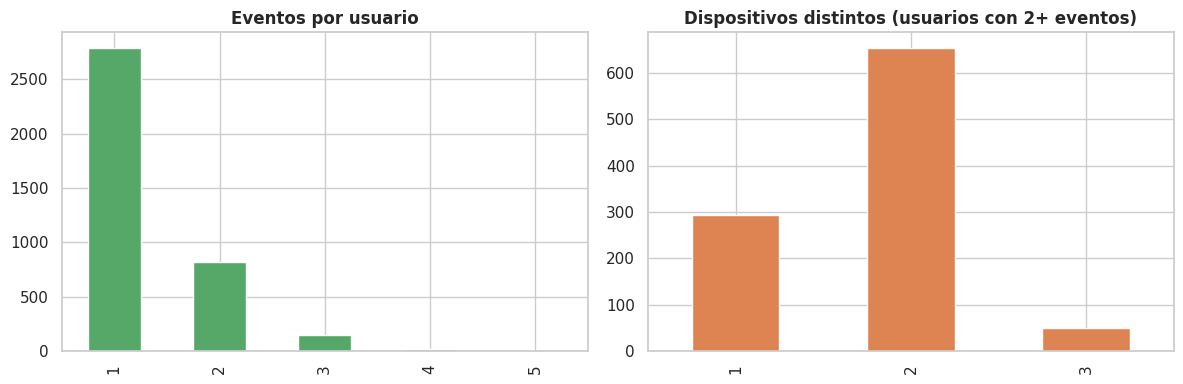

Usuarios con 2+ eventos que usan más de un dispositivo: 70.6%


In [33]:
# Usuarios: ¿cuántos eventos tiene cada uno?
por_usuario = logs.groupby("user_id").agg(eventos=("event_id", "size"),
                                          dispositivos=("device", "nunique"),
                                          compras=("es_compra", "sum"))
print(f"Usuarios únicos: {len(por_usuario):,} | usuarios con 2+ eventos: {(por_usuario.eventos > 1).sum():,}")
print(f"Usuarios con compra: {(por_usuario.compras > 0).sum():,} ({(por_usuario.compras > 0).mean():.1%})")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
por_usuario["eventos"].value_counts().sort_index().plot.bar(ax=ax[0], color="#55A868"); ax[0].set_title("Eventos por usuario"); ax[0].set_xlabel("")
multi = por_usuario[por_usuario.eventos > 1]
multi["dispositivos"].value_counts().sort_index().plot.bar(ax=ax[1], color="#DD8452")
ax[1].set_title("Dispositivos distintos (usuarios con 2+ eventos)"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()
print(f"Usuarios con 2+ eventos que usan más de un dispositivo: {(multi.dispositivos > 1).mean():.1%}")

## 12. Embudo de conversión
Etapas: `page_view → search → add_to_cart → checkout_start → purchase`. `remove_from_cart` no es una etapa, se analiza aparte.

,eventos,usuarios,% vs etapa anterior (eventos),% vs page_view (eventos)
event_type,,,,
page_view,815,786,NaN,100.00
search,815,774,100.00,100.00
add_to_cart,858,820,105.28,105.28
checkout_start,793,760,92.42,97.30
purchase,826,787,104.16,101.35


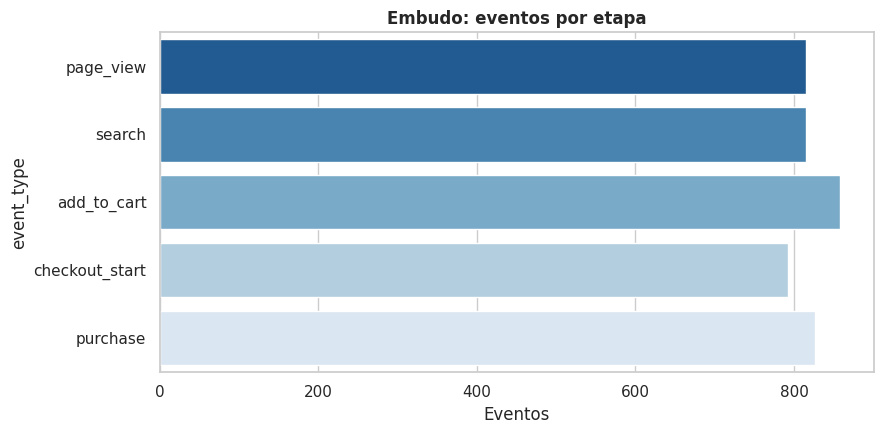

remove_from_cart: 893 eventos
Compras / add_to_cart: 96.3% | Compras / checkout_start: 104.2%


In [34]:
embudo = logs[logs["event_type"].isin(etapas_embudo)].groupby("event_type", observed=True).agg(
    eventos=("event_id", "size"), usuarios=("user_id", "nunique")).reindex(etapas_embudo)
embudo["% vs etapa anterior (eventos)"] = embudo["eventos"].pct_change().add(1).mul(100)
embudo["% vs page_view (eventos)"] = embudo["eventos"] / embudo["eventos"].iloc[0] * 100
display(embudo)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(x=embudo["eventos"].values, y=embudo.index.astype(str), ax=ax, palette="Blues_r", hue=embudo.index.astype(str), legend=False)
ax.set_title("Embudo: eventos por etapa"); ax.set_xlabel("Eventos")
plt.tight_layout(); plt.show()

print("remove_from_cart:", (logs["event_type"] == "remove_from_cart").sum(), "eventos")
print(f"Compras / add_to_cart: {embudo.loc['purchase','eventos'] / embudo.loc['add_to_cart','eventos']:.1%} | "
      f"Compras / checkout_start: {embudo.loc['purchase','eventos'] / embudo.loc['checkout_start','eventos']:.1%}")

In [35]:
# Prueba de coherencia: ¿cada compra tiene un checkout_start previo del mismo usuario?
primer_checkout = logs[logs["event_type"] == "checkout_start"].groupby("user_id")["timestamp"].min()
compras = logs[logs["es_compra"]].copy()
compras["checkout_previo"] = compras["user_id"].map(primer_checkout) < compras["timestamp"]
n_eventos_usuario = compras["user_id"].map(logs["user_id"].value_counts())

print(f"Compras con checkout_start previo del mismo usuario: {compras['checkout_previo'].sum():,} de {len(compras):,} ({compras['checkout_previo'].mean():.1%})")
print(f"Compras de usuarios que no tienen ningún otro evento: {(n_eventos_usuario == 1).mean():.1%}")

Compras con checkout_start previo del mismo usuario: 31 de 826 (3.8%)
Compras de usuarios que no tienen ningún otro evento: 58.5%


## 13. Dispositivo, categoría y comportamiento de sesión

In [36]:
for c in ["device", "product_category"]:
    t = (logs.groupby(c).agg(eventos=("event_id", "size"), compras=("es_compra", "sum"),
                             duracion_media=("session_duration_sec", "mean"), duracion_mediana=("session_duration_sec", "median")))
    t["% eventos que son compra"] = t["compras"] / t["eventos"] * 100
    display(t.sort_values("eventos", ascending=False))

,eventos,compras,duracion_media,duracion_mediana,% eventos que son compra
device,,,,,
mobile,1679,275,885.35,873.00,16.38
desktop,1669,270,889.39,885.00,16.18
tablet,1652,281,901.77,866.00,17.01


,eventos,compras,duracion_media,duracion_mediana,% eventos que son compra
product_category,,,,,
home,1020,168,904.33,892.50,16.47
electronics,1012,184,846.89,801.50,18.18
clothing,1001,148,927.87,951.00,14.79
sports,986,166,902.83,883.50,16.84
beauty,981,160,878.88,860.00,16.31


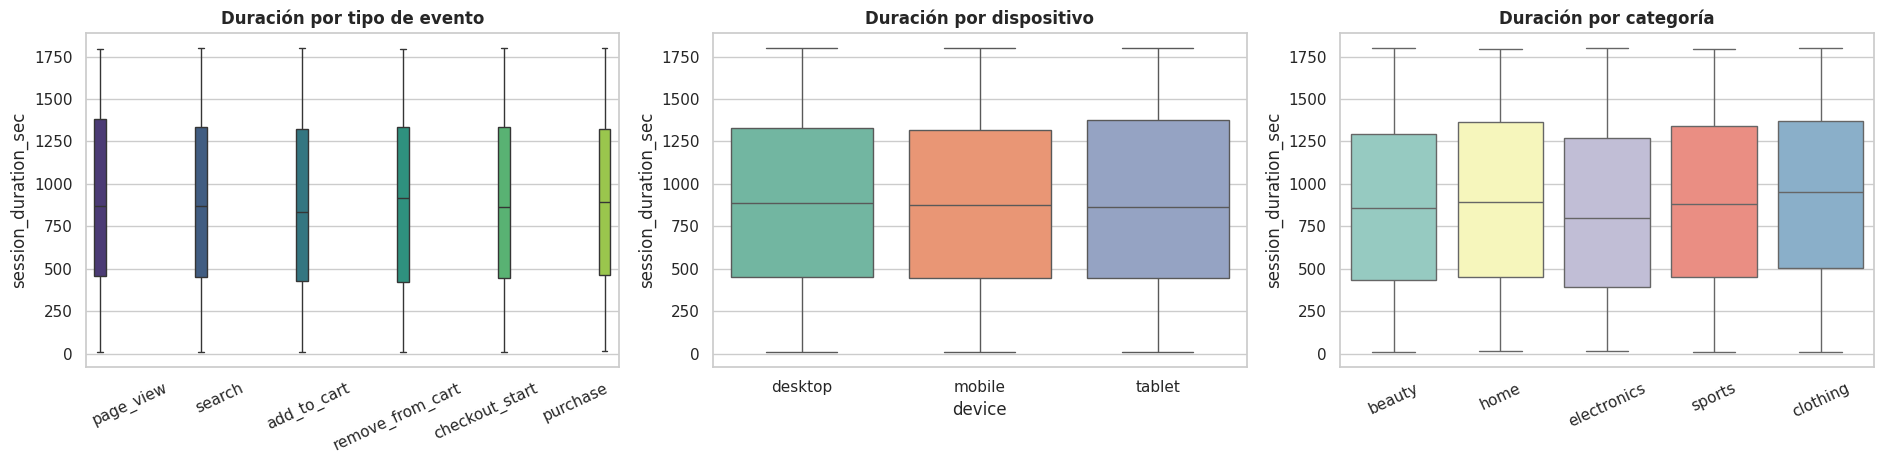

In [37]:
fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
sns.boxplot(data=logs, x="event_type", y="session_duration_sec", order=orden_eventos, ax=ax[0], palette="viridis", hue="event_type", legend=False)
ax[0].set_title("Duración por tipo de evento"); ax[0].tick_params(axis="x", rotation=25); ax[0].set_xlabel("")
sns.boxplot(data=logs, x="device", y="session_duration_sec", ax=ax[1], palette="Set2", hue="device", legend=False); ax[1].set_title("Duración por dispositivo")
sns.boxplot(data=logs, x="product_category", y="session_duration_sec", ax=ax[2], palette="Set3", hue="product_category", legend=False)
ax[2].set_title("Duración por categoría"); ax[2].tick_params(axis="x", rotation=25); ax[2].set_xlabel("")
plt.tight_layout(); plt.show()

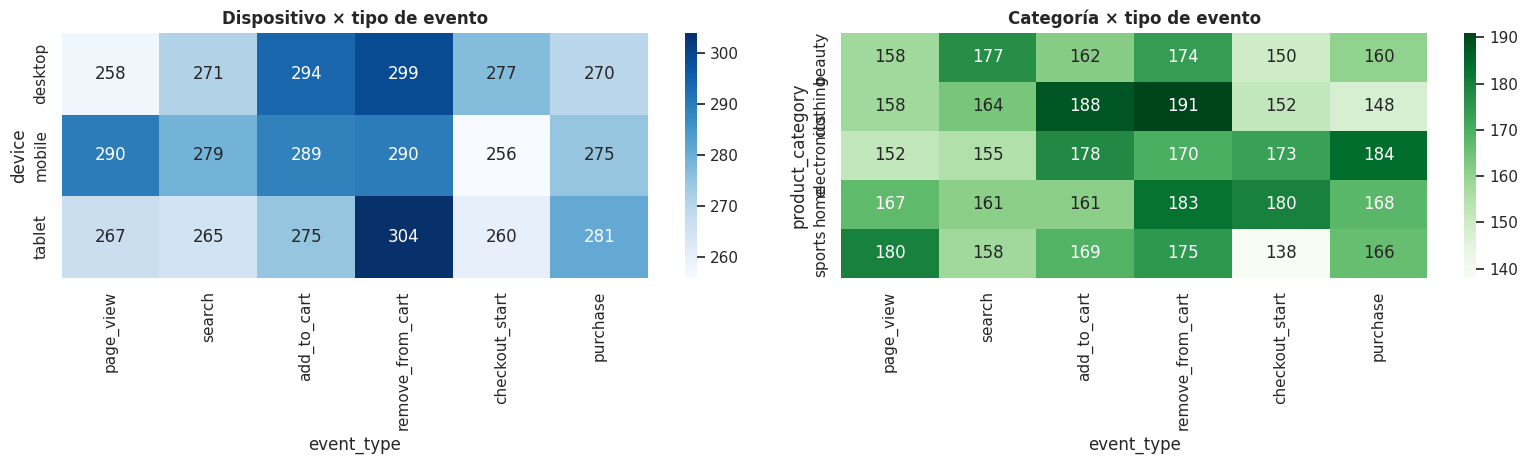

── Asociación entre variables categóricas (chi-cuadrado de independencia) ──
  device            × event_type        χ²=   4.3 gl=10 p=0.9321 → independientes
  product_category  × event_type        χ²=  19.9 gl=20 p=0.4615 → independientes
  device            × product_category  χ²=   9.6 gl= 8 p=0.2932 → independientes

── ¿La duración de sesión difiere entre grupos? (Kruskal-Wallis) ──
  event_type        H=  1.56 p=0.9064 → sin diferencia significativa
  device            H=  0.85 p=0.6540 → sin diferencia significativa
  product_category  H= 14.21 p=0.0066 → difiere
  dia_semana        H=  4.60 p=0.5963 → sin diferencia significativa

── ¿La conversión (% de eventos que son compra) difiere? ──
  device            χ²=  0.45 p=0.7971 → sin diferencia significativa
  product_category  χ²=  4.32 p=0.3650 → sin diferencia significativa


In [38]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
sns.heatmap(pd.crosstab(logs["device"], logs["event_type"]), annot=True, fmt="d", cmap="Blues", ax=ax[0]); ax[0].set_title("Dispositivo × tipo de evento")
sns.heatmap(pd.crosstab(logs["product_category"], logs["event_type"]), annot=True, fmt="d", cmap="Greens", ax=ax[1]); ax[1].set_title("Categoría × tipo de evento")
plt.tight_layout(); plt.show()

print("── Asociación entre variables categóricas (chi-cuadrado de independencia) ──")
for a, b in [("device", "event_type"), ("product_category", "event_type"), ("device", "product_category")]:
    chi, p, dof, _ = stats.chi2_contingency(pd.crosstab(logs[a], logs[b]))
    print(f"  {a:17s} × {b:17s} χ²={chi:6.1f} gl={dof:2d} p={p:.4f} →", "asociadas" if p < .05 else "independientes")

print("\n── ¿La duración de sesión difiere entre grupos? (Kruskal-Wallis) ──")
for c in ["event_type", "device", "product_category", "dia_semana"]:
    h, p = stats.kruskal(*[g["session_duration_sec"].values for _, g in logs.groupby(c, observed=True)])
    print(f"  {c:17s} H={h:6.2f} p={p:.4f} →", "difiere" if p < .05 else "sin diferencia significativa")

print("\n── ¿La conversión (% de eventos que son compra) difiere? ──")
for c in ["device", "product_category"]:
    chi, p, _, _ = stats.chi2_contingency(pd.crosstab(logs[c], logs["es_compra"]))
    print(f"  {c:17s} χ²={chi:6.2f} p={p:.4f} →", "difiere" if p < .05 else "sin diferencia significativa")

## 14. Patrones temporales de los logs

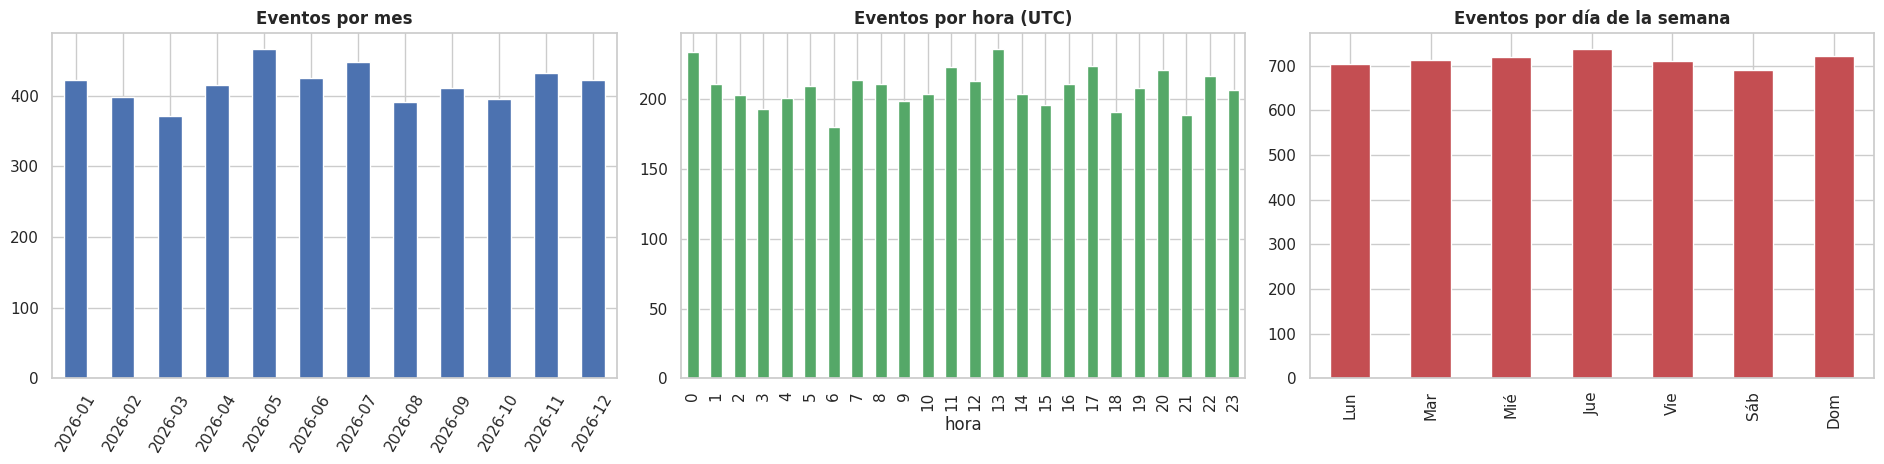

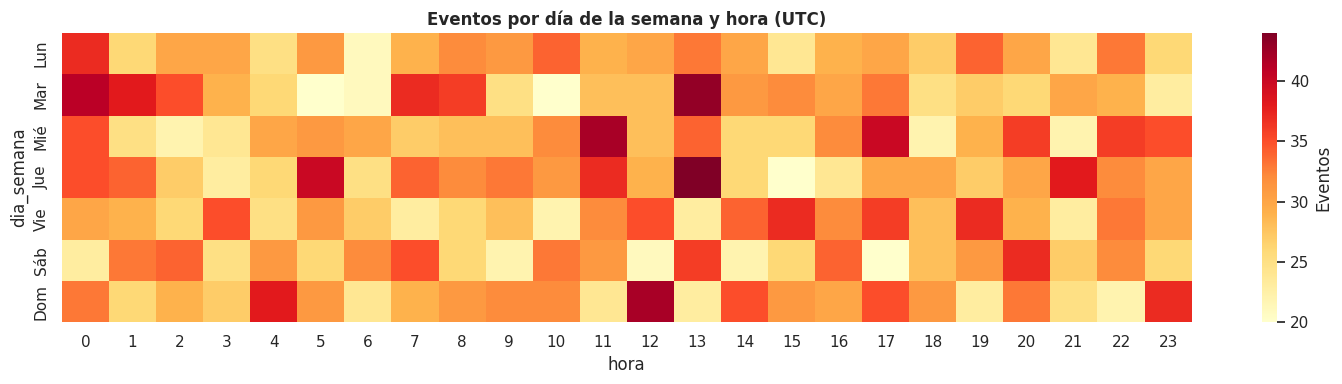

Uniformidad por mes               χ²= 17.30 p=0.0993 → compatible con uniforme
Uniformidad por hora              χ²= 20.50 p=0.6114 → compatible con uniforme
Uniformidad por día de la semana  χ²=  1.77 p=0.9395 → compatible con uniforme


In [39]:
fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
logs.groupby("mes").size().plot.bar(ax=ax[0], color="#4C72B0"); ax[0].set_title("Eventos por mes"); ax[0].set_xlabel(""); ax[0].tick_params(axis="x", rotation=60)
logs.groupby("hora").size().reindex(range(24), fill_value=0).plot.bar(ax=ax[1], color="#55A868"); ax[1].set_title("Eventos por hora (UTC)")
logs.groupby("dia_semana", observed=False).size().plot.bar(ax=ax[2], color="#C44E52"); ax[2].set_title("Eventos por día de la semana"); ax[2].set_xlabel("")
plt.tight_layout(); plt.show()

heat = logs.pivot_table(index="dia_semana", columns="hora", values="event_id", aggfunc="size", observed=False)
plt.figure(figsize=(15, 4)); sns.heatmap(heat, cmap="YlOrRd", cbar_kws={"label": "Eventos"}); plt.title("Eventos por día de la semana y hora (UTC)")
plt.tight_layout(); plt.show()

for nombre, serie in [("mes", logs["mes"]), ("hora", logs["hora"]), ("día de la semana", logs["dia_semana"])]:
    chi, p = stats.chisquare(serie.value_counts())
    print(f"Uniformidad por {nombre:17s} χ²={chi:6.2f} p={p:.4f} →", "NO uniforme" if p < .05 else "compatible con uniforme")

## 15. Cruce con las transacciones (POS)
Los logs **no tienen monto, tienda ni ID de pedido**, y sus **categorías están en inglés y no coinciden** con las del POS, por lo que el cruce solo puede hacerse por **fecha**, y únicamente en la ventana donde ambas fuentes tienen datos.

Categorías POS:  ['Aseo', 'Bebidas', 'Carnes', 'Frutas', 'Granos', 'Licores', 'Lácteos', 'Panadería', 'Snacks', 'Verduras']
Categorías logs: ['beauty', 'clothing', 'electronics', 'home', 'sports']
¿Coinciden?      False

Ventana común: 2026-09-15 → 2026-10-15 | eventos online: 404 | transacciones POS: 5,000
Correlación de Spearman diaria (n=31 días): ρ=-0.004  p=0.982


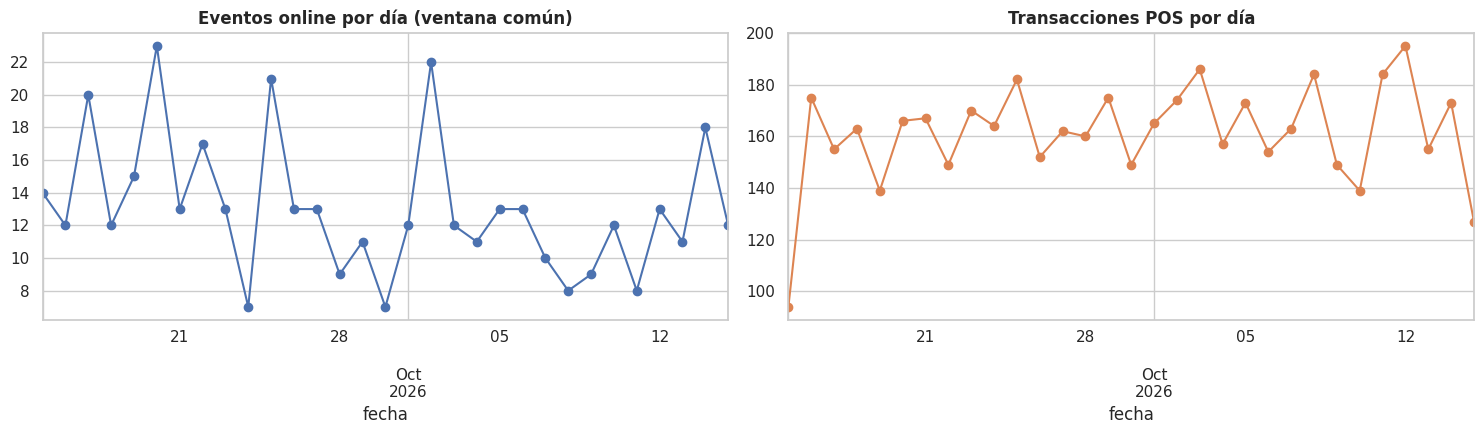

In [40]:
print("Categorías POS: ", sorted(df["product_category"].unique()))
print("Categorías logs:", sorted(logs["product_category"].unique()))
print("¿Coinciden?     ", set(df["product_category"]) == set(logs["product_category"]))

ini, fin = df["timestamp"].min().normalize(), df["timestamp"].max()
ventana = logs[(logs["timestamp"] >= ini) & (logs["timestamp"] <= fin)]
print(f"\nVentana común: {ini.date()} → {fin.date()} | eventos online: {len(ventana):,} | transacciones POS: {len(df):,}")

diario = pd.concat([ventana.groupby("fecha").size().rename("eventos_online"),
                    df.groupby("fecha").size().rename("transacciones_pos")], axis=1).fillna(0)
rho, p = stats.spearmanr(diario["eventos_online"], diario["transacciones_pos"])
print(f"Correlación de Spearman diaria (n={len(diario)} días): ρ={rho:.3f}  p={p:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
diario["eventos_online"].plot(ax=ax[0], marker="o", color="#4C72B0"); ax[0].set_title("Eventos online por día (ventana común)")
diario["transacciones_pos"].plot(ax=ax[1], marker="o", color="#DD8452"); ax[1].set_title("Transacciones POS por día")
plt.tight_layout(); plt.show()

### Conclusiones de la Parte 2

**Calidad de datos**
- 5.000 eventos de 3.792 usuarios, sin nulos, sin `event_id` duplicados y con formatos de ID consistentes.
- El archivo viene ordenado por `event_id`, no por fecha, y los timestamps están en **UTC** (sufijo `Z`).
- **Fechas futuras:** el rango llega hasta el 31-dic-2026 y **1.066 eventos (21,3 %)** son posteriores al último registro del POS (15-oct-2026). Hay que confirmar la zona horaria y cómo se generó la fecha.
- Las **categorías no coinciden con el POS**: los logs usan 5 en inglés (`beauty`, `clothing`, `electronics`, `home`, `sports`) y el POS tiene 10 en español (Lácteos, Carnes, etc.). Los logs además incluyen `remove_from_cart`.

**Comportamiento**
- Todo es **muy uniforme**: tipos de evento (16-18 % cada uno), dispositivos (~33 %), categorías (~20 %), meses, horas y días de la semana son compatibles con una distribución uniforme. La duración de sesión va de 10 a 1.800 s (media 892, mediana 875) y se parece mucho a una uniforme.
- **Conversión simple:** el 16,5 % de los eventos son compras y el 20,8 % de los usuarios tiene al menos una. No hay diferencias significativas por dispositivo (16,2-17,0 %, p = 0,80) ni por categoría (de 14,8 % en `clothing` a 18,2 % en `electronics`, p = 0,37).
- **Único efecto detectado:** la duración de sesión difiere por categoría (p = 0,007): `electronics` tiene la mediana más baja (~800 s) y `clothing` la más alta (~950 s). Es un efecto modesto, pero se mantiene tras corregir por las 4 pruebas de duración (Bonferroni, p ≈ 0,03).

**Coherencia del embudo (señales de alerta)**
- Las compras (826) superan a los `checkout_start` (793), y las compras equivalen al 96 % de los `add_to_cart`: un embudo real se angosta etapa tras etapa.
- Solo **3,8 %** de las compras tienen un `checkout_start` previo del mismo usuario, y el **58,5 %** de las compras son de usuarios sin ningún otro evento.
- El **70,6 %** de los usuarios con 2+ eventos aparece en más de un dispositivo.
- En conjunto, `user_id` y los eventos no forman sesiones coherentes: **no es posible calcular una conversión de embudo confiable** con este archivo, y el patrón es consistente con datos simulados o generados al azar.

**Cruce con el POS**
- En la ventana común (15-sep a 15-oct) hay solo 404 eventos online (~13 por día) frente a 5.000 transacciones POS, y la correlación diaria es nula (ρ ≈ 0, p = 0,98). Sin tienda, monto ni categorías equivalentes, no se puede conectar ambas fuentes más allá de la fecha.

**Siguientes pasos**
1. Confirmar el origen de los logs, la zona horaria y por qué hay fechas posteriores al corte.
2. Definir un mapeo entre las categorías online y las del POS.
3. Agregar `session_id`, ID de pedido y monto en `purchase` para medir conversión e ingreso online.
4. Validar la lógica de generación de `user_id` y `device` (mismo usuario en varios dispositivos en un 70 % de los casos).